# Stress-period labels

**Owner:** Salah · **Week 1** · Stress labels & benchmarks · Rule proposal: `docs/stress_label_rule.md`

Builds the labeled table of stress dates from the proposed rule:

* centered 21-trading-day realized volatility of `^GSPC`, annualized
* stress day if it is **at least 25%**
* stress days less than 20 trading days apart are one episode; episodes shorter than 10 trading days are dropped

**Labels use future returns by design** (the window looks 10 days ahead). They are evaluation targets only and must never be used as model features.

**Before running:** `python scripts/download_sp500_prices.py`. If `data/processed/daily_panel.parquet` exists, Section 5 checks the episodes against VIX and STLFSI4 (validation only; the labels never use them).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import stress_labels as sl

PROC = ROOT / "data" / "processed"
gspc = pd.read_parquet(PROC / "sp500_close.parquet")["^GSPC"].dropna()
print(f"^GSPC: {gspc.index[0].date()} to {gspc.index[-1].date()}, {len(gspc)} trading days")

^GSPC: 2005-01-03 to 2026-10-26, 5488 trading days


## 1. Daily labels and episode table

In [2]:
labels = sl.daily_labels(gspc)
episodes = sl.episode_table(labels, gspc)

labeled = labels["stress"].dropna()
print(f"Labeled days: {labeled.index[0].date()} to {labeled.index[-1].date()} "
      f"(first and last {sl.WINDOW // 2} trading days cannot be labeled)")
print(f"{len(episodes)} episodes, {int(labeled.sum())} stress days = {labeled.mean():.1%} of labeled days")
episodes

Labeled days: 2005-01-19 to 2026-10-12 (first and last 10 trading days cannot be labeled)
13 episodes, 630 stress days = 11.5% of labeled days


,start,end,trading_days,peak_vol,peak_vol_date,max_drawdown_252d,trough_date,name
episode_id,,,,,,,,
1,2007-08-03,2007-08-17,11,0.253,2007-08-17,-0.094,2007-08-15,Aug 2007 credit and quant-fund stress
2,2008-03-04,2008-04-02,21,0.309,2008-03-18,-0.186,2008-03-10,Bear Stearns
3,2008-08-29,2009-05-26,185,0.863,2008-10-14,-0.526,2009-03-09,Global financial crisis (Lehman)
4,2010-04-26,2010-06-16,37,0.339,2010-05-20,-0.137,2010-06-07,Flash crash and first euro-area debt stress
5,2011-07-25,2011-12-08,97,0.490,2011-08-16,-0.194,2011-10-03,"U.S. debt ceiling, S&P downgrade and euro-area..."
6,2015-08-12,2015-09-10,21,0.319,2015-09-03,-0.124,2015-08-25,China devaluation selloff
7,2018-02-01,2018-02-20,13,0.266,2018-02-16,-0.102,2018-02-08,Feb 2018 volatility spike
8,2018-12-11,2019-01-09,20,0.319,2018-12-19,-0.198,2018-12-24,Q4 2018 selloff
9,2020-02-14,2020-06-25,92,0.968,2020-03-23,-0.339,2020-03-23,COVID-19 crash


## 2. Chart: volatility, threshold and episodes

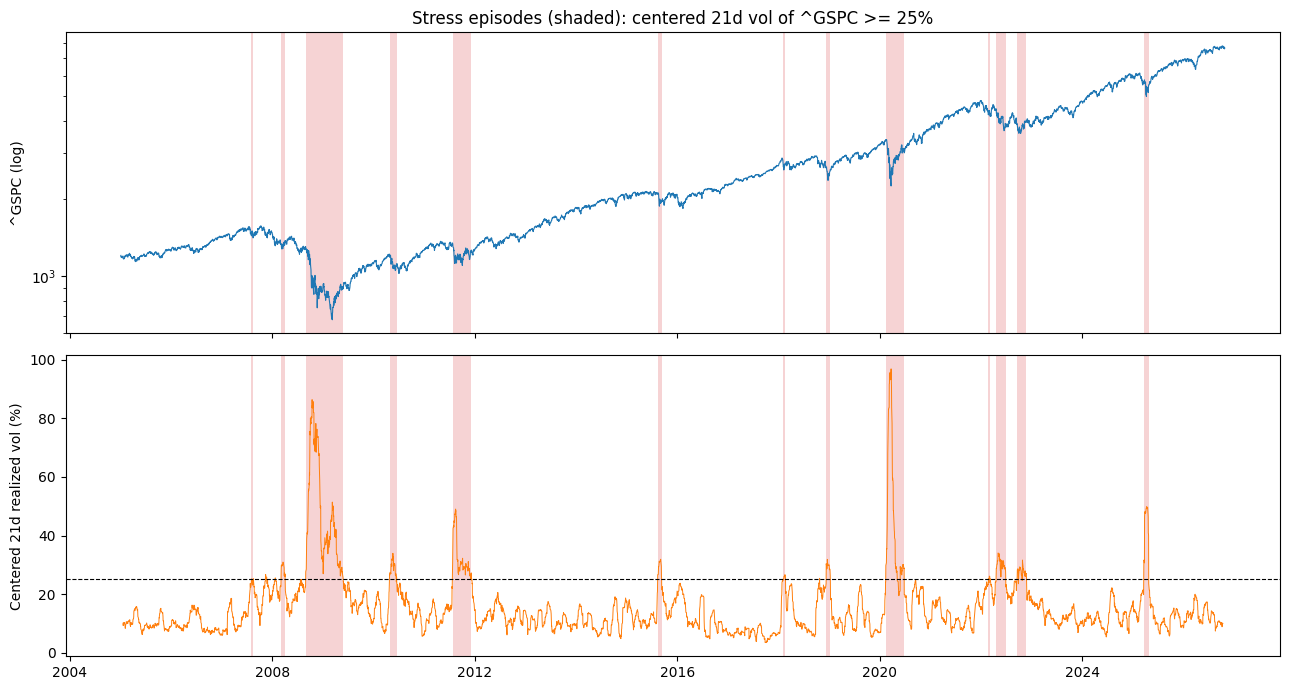

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(gspc.index, gspc, lw=0.8); axes[0].set_yscale("log"); axes[0].set_ylabel("^GSPC (log)")
axes[1].plot(labels.index, labels["vol_centered"] * 100, lw=0.7, color="tab:orange")
axes[1].axhline(sl.THRESHOLD * 100, color="black", ls="--", lw=0.8)
axes[1].set_ylabel("Centered 21d realized vol (%)")
for ax in axes:
    for _, ep in episodes.iterrows():
        ax.axvspan(pd.Timestamp(ep["start"]), pd.Timestamp(ep["end"]), color="tab:red", alpha=0.2, lw=0)
axes[0].set_title("Stress episodes (shaded): centered 21d vol of ^GSPC >= 25%")
plt.tight_layout(); plt.show()

## 3. Sensitivity: how much do the episodes depend on the choices?

Each row changes one setting from the proposed rule. "Trailing" uses the usual backward-looking 20-day window instead of the centered one; compare the start dates to see how much later a trailing window would start each episode.

In [4]:
def run(threshold=sl.THRESHOLD, window=sl.WINDOW, centered=True, gap=sl.MERGE_GAP, min_len=sl.MIN_LENGTH):
    lab = sl.daily_labels(gspc, threshold=threshold, window=window, merge_gap=gap,
                          min_length=min_len, centered=centered)
    return lab, sl.episode_table(lab, gspc)

variants = {
    "Proposed (centered 21d, 25%)": {},
    "Threshold 20%": {"threshold": 0.20},
    "Threshold 30%": {"threshold": 0.30},
    "Trailing 20d window, 25%": {"centered": False, "window": 20},
    "Merge gap 10 days": {"gap": 10},
    "Min length 5 days": {"min_len": 5},
}
summary, starts = [], {}
for name, kw in variants.items():
    lab, ep = run(**kw)
    summary.append({"variant": name, "episodes": len(ep),
                    "stress share of days": round(lab["stress"].mean(), 3)})
    starts[name] = ep
display(pd.DataFrame(summary).set_index("variant"))

,episodes,stress share of days
variant,,
"Proposed (centered 21d, 25%)",13,0.115
Threshold 20%,17,0.224
Threshold 30%,8,0.073
"Trailing 20d window, 25%",14,0.115
Merge gap 10 days,14,0.113
Min length 5 days,14,0.117


In [5]:
# Start dates of the proposed episodes vs the trailing-window version
prop = starts["Proposed (centered 21d, 25%)"][["start", "end", "name"]].copy()
trail = starts["Trailing 20d window, 25%"]
def nearest_trailing_start(row):
    s, e = pd.Timestamp(row["start"]), pd.Timestamp(row["end"])
    hit = trail[(pd.to_datetime(trail["end"]) >= s) & (pd.to_datetime(trail["start"]) <= e)]
    return hit["start"].iloc[0] if len(hit) else None
prop["trailing start"] = prop.apply(nearest_trailing_start, axis=1)
prop["trading days later"] = [
    (gspc.index.get_loc(pd.Timestamp(t)) - gspc.index.get_loc(pd.Timestamp(s))) if t else None
    for s, t in zip(prop["start"], prop["trailing start"])
]
prop

,start,end,name,trailing start,trading days later
episode_id,,,,,
1,2007-08-03,2007-08-17,Aug 2007 credit and quant-fund stress,2007-08-17,10
2,2008-03-04,2008-04-02,Bear Stearns,2008-03-18,10
3,2008-08-29,2009-05-26,Global financial crisis (Lehman),2008-09-15,10
4,2010-04-26,2010-06-16,Flash crash and first euro-area debt stress,2010-05-10,10
5,2011-07-25,2011-12-08,"U.S. debt ceiling, S&P downgrade and euro-area...",2011-08-08,10
6,2015-08-12,2015-09-10,China devaluation selloff,2015-08-26,10
7,2018-02-01,2018-02-20,Feb 2018 volatility spike,2018-02-14,9
8,2018-12-11,2019-01-09,Q4 2018 selloff,2018-12-26,10
9,2020-02-14,2020-06-25,COVID-19 crash,2020-03-02,10


## 4. Check against key dates from the four EDA periods

A useful rule should put the acute phase of each EDA period inside a labeled episode. The 2020 and 2022 dates are taken from the `^GSPC` data itself.

In [6]:
eda_dates = {
    "2008-09-15": "Lehman bankruptcy (2008 EDA)",
    "2011-08-08": "First trading day after S&P downgrade (2011 EDA)",
    "2020-03-16": "Largest 2020 daily fall in ^GSPC (-12.0%)",
    "2022-06-13": "^GSPC first closes 20% below its Jan 2022 high",
    "2022-10-12": "2022 closing low of ^GSPC",
}
rows = []
for d, what in eda_dates.items():
    t = gspc.index[gspc.index.get_indexer([pd.Timestamp(d)], method="bfill")[0]]
    eid = labels.loc[t, "episode_id"]
    rows.append({"date": t.date(), "event": what, "in episode": bool(pd.notna(eid)),
                 "episode": episodes.loc[int(eid), "name"] if pd.notna(eid) else None})
pd.DataFrame(rows)

,date,event,in episode,episode
0,2008-09-15,Lehman bankruptcy (2008 EDA),True,Global financial crisis (Lehman)
1,2011-08-08,First trading day after S&P downgrade (2011 EDA),True,"U.S. debt ceiling, S&P downgrade and euro-area..."
2,2020-03-16,Largest 2020 daily fall in ^GSPC (-12.0%),True,COVID-19 crash
3,2022-06-13,^GSPC first closes 20% below its Jan 2022 high,True,2022 rate-hike bear market (first leg)
4,2022-10-12,2022 closing low of ^GSPC,True,2022 rate-hike bear market (second leg)


## 5. Validation against VIX and STLFSI4 (optional)

Runs only if `daily_panel.parquet` exists. The labels never use these series; this only checks that our episodes are periods the standard indexes also call stressful (STLFSI4 above 0 means above-average stress; VIX above 30 is a common rule of thumb).

In [7]:
panel_path = PROC / "daily_panel.parquet"
if not panel_path.exists():
    print("daily_panel.parquet not found; run 01_data_collection.ipynb to add this check.")
else:
    panel = pd.read_parquet(panel_path)
    bench = pd.DataFrame(index=gspc.index)
    if "VIXCLS" in panel:
        bench["VIX"] = panel["VIXCLS"].reindex(gspc.index).ffill()
    if "STLFSI4" in panel:
        bench["STLFSI4"] = panel["STLFSI4"].ffill().reindex(gspc.index, method="ffill")
    bench["stress"] = labels["stress"]
    print("Mean benchmark level inside vs outside episodes:")
    display(bench.groupby("stress").mean().round(2))
    per_ep = []
    for eid, ep in episodes.iterrows():
        b = bench.loc[str(ep["start"]):str(ep["end"])]
        per_ep.append({"episode": ep["name"], **{f"max {c}": round(b[c].max(), 2) for c in b if c != "stress"}})
    display(pd.DataFrame(per_ep))

daily_panel.parquet not found; run 01_data_collection.ipynb to add this check.


## 6. Save

In [8]:
PROC.mkdir(parents=True, exist_ok=True)
labels.to_parquet(PROC / "stress_labels_daily.parquet")
episodes.to_csv(PROC / "stress_periods.csv")
# Small copy committed to git (data/ is gitignored) so the team can see the table on GitHub
episodes.to_csv(ROOT / "docs" / "stress_periods.csv")
print("Saved data/processed/stress_labels_daily.parquet, data/processed/stress_periods.csv, docs/stress_periods.csv")

Saved data/processed/stress_labels_daily.parquet, data/processed/stress_periods.csv, docs/stress_periods.csv
